D603 Machine Learning Task 3
Donovan Hall

B1.  Summarize one research question that is relevant to a real-world organizational situation captured in the selected dataset and that you will answer using time series modeling techniques.

Time series models take an aggregation of data to a report of response over time. By introducing the rule that Time both matters and is an independent variable an analyst can find insights that are hidden from other techniques. Results from a time series analysis can forcast future drops of revenue and reveal areas of concern to leadership, and like the unsupervised machine learning analysis done earlier, can group customers in a way that allows for targeted retention strategies.
The question I will be answering in this analysis is: Can I analyze the dataset using a time series modeling technique and predict one business quarter worth of data using the 2 years of information on hand?

B2.  Define the objectives or goals of the data analysis. Ensure that your objectives or goals are reasonable within the scope of the scenario and are represented in the available data.

This analysis aims to run the dataset through a time series analysis to analyze historic trends and forcast future changes to revenue. The parent company should be able to analyze this report to better understand historic patterns and gain a rough prediciton of future profits.

C.  Summarize the assumptions of a time series model including stationarity and autocorrelated data.

There are two aspects a time series model: the stationarity of the data, and the residuals of the model. Stationarity is made up of three components: constant mean, variance, and autocorrelation. 
A constant mean means that the long term average does not change over time. In a plot this means the slope of the trend line is as flat as possible.
A constant variance means that the standard deviation per time period is equivalent. It is similar to the difference between speed and acceleration. 
Autocorrelation is a measure of how strongly a complete time series is related to a previous, complete series. A constant autocorrelation means that the relationship between time periods stays the same. In this example where there are multiple years worth of data, if there is a spike between April and May revenue, then the spike should be similar year on year.

After the model is built, it’s performance is rated by analyzing the residuals, or differences between the predictions and actual values. The more random a models residuals, the more accurate the model is. The mean of a model’s residuals should be zero, or else it over or under predicts. There should also be no autocorrelation in the residuals. If there is, then that is a sign the model is missing a pattern in the data. Finally, the residuals should be normally distributed. The further the model gets from a normal distribution, the worse its confidence intervals are. 

D1.  Provide a line graph visualizing the realization of the time series.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

pd.set_option('display.max_columns', None) # view all columns when printing
spacer = "*"*20
def header_txt(message):
    output = f"\n{spacer} {message} {spacer}\n"
    print(output)


path = "C:/CraneDev/python_projects/wgu/d603/task3/"
# path = "D:/programming_workspace/WGU/d603/task3/"
file = "churn_clean.csv"
df = pd.read_csv(f"{path}{file}")
print(df.head())


# origial data is daily
daily_data = df

# divide by 7 to group by weeks
df['Week'] = (df['Day'] - 1) // 7
weekly_data = df.groupby('Week')['Revenue'].sum().reset_index()
weekly_data = weekly_data.iloc[:-1] #remove the partial week as that would throw off the analysis

# divide by 30 to get a decent approximation of months
df['Month'] = (df['Day'] - 1) // 30
monthly_data = df.groupby('Month')['Revenue'].sum().reset_index()
monthly_data = monthly_data.iloc[:-1] #remove the partial month as that would throw off the analysis

header_txt("Construct Subplots")
fig, axes = plt.subplots(3, 1, figsize=(11, 11))
fig.suptitle('Revenue at Different Time Granularities', fontsize=20, fontweight='bold')


# daily plot
axes[0].plot(daily_data['Day'], daily_data['Revenue'], label='Daily Revenue', color='blue')
axes[0].set_title('Daily View', fontsize=14)
axes[0].set_ylabel('Revenue ($)', fontsize=12)
axes[0].set_xlabel('Day Number', fontsize=12)
axes[0].grid(True, linestyle='--', linewidth=0.5)
axes[0].legend()


# weekly plot
axes[1].plot(weekly_data['Week'], weekly_data['Revenue'], label='Weekly Revenue', color='magenta')
axes[1].set_title('Weekly View', fontsize=14)
axes[1].set_ylabel('Total Weekly Revenue ($)', fontsize=12)
axes[1].set_xlabel('Week Number', fontsize=12)
axes[1].grid(True, linestyle='--', linewidth=0.5)
axes[1].legend()


# monthly plot
axes[2].plot(monthly_data['Month'], monthly_data['Revenue'], label='Monthly Revenue', color='green')
axes[2].set_title('Monthly View (30-day periods)', fontsize=14)
axes[2].set_ylabel('Total Monthly Revenue ($)', fontsize=12)
axes[2].set_xlabel('Month Number (30-day period)', fontsize=12)
axes[2].grid(True, linestyle='--', linewidth=0.5)
axes[2].legend()


# formatting initial realizations
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(f"{path}time_step_realization")

ModuleNotFoundError: No module named 'statsmodels'

D2.  Describe the time step formatting of the realization, including any gaps in measurement and the length of the sequence.

The raw data is 2 years of revenue data with no gaps in measurements and 731 unique days of data. The initial time step is daily, but I will be including analysis on both weekly (7 day) and monthly (30 day) time steps.

D3.  Evaluate the stationarity of the time series.

The provided raw data does not have strong stationarity. There is an obvious upward trend (constant mean) to the data, and the daily/weekly plots show that there are noticeable swings in the data (constant variance). Finally, the weekly plot show that there is some seasonality to the data. While this might not be a penalty to the data’s stationarity, that would only be the case if the trends are stable.

D4.  Explain the steps used to prepare the data for analysis, including the training and test set split.

The first thing I did was to group my data into weeks and months and plotted the data. After that, I calculated the change in revenue by using the diff() function, which fixes the non-constant mean. I graphed this change in comparison to the raw data, shown below. Finally, I split my data in to a train and test split. Because this data needs to stay in chronological order, I couldn’t use the testtrainsplit() function I have used in previous labs. To split my data I was able to take the int(len()) of my data and spit it into an 80/20 split. Finally, I graphed my split data, shown below.


******************** Plotting Change in Revenues ********************


******************** test/train split ********************



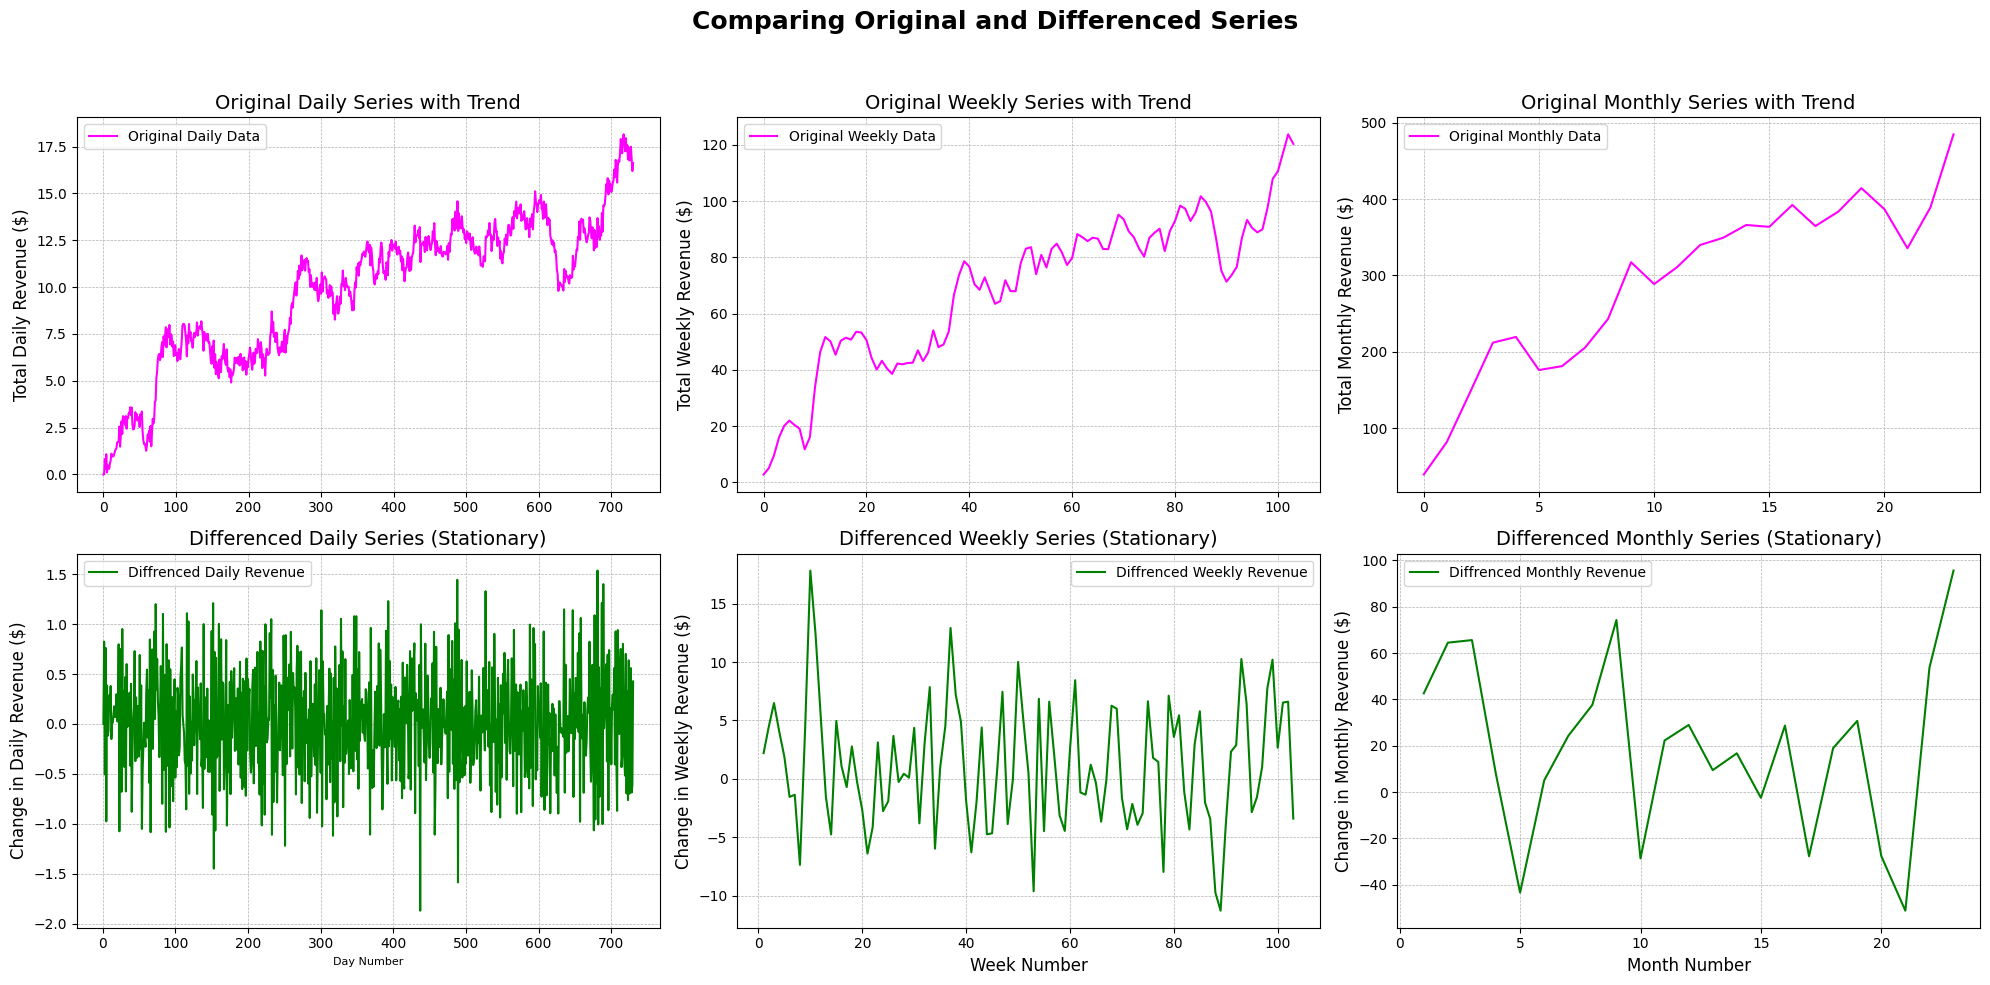

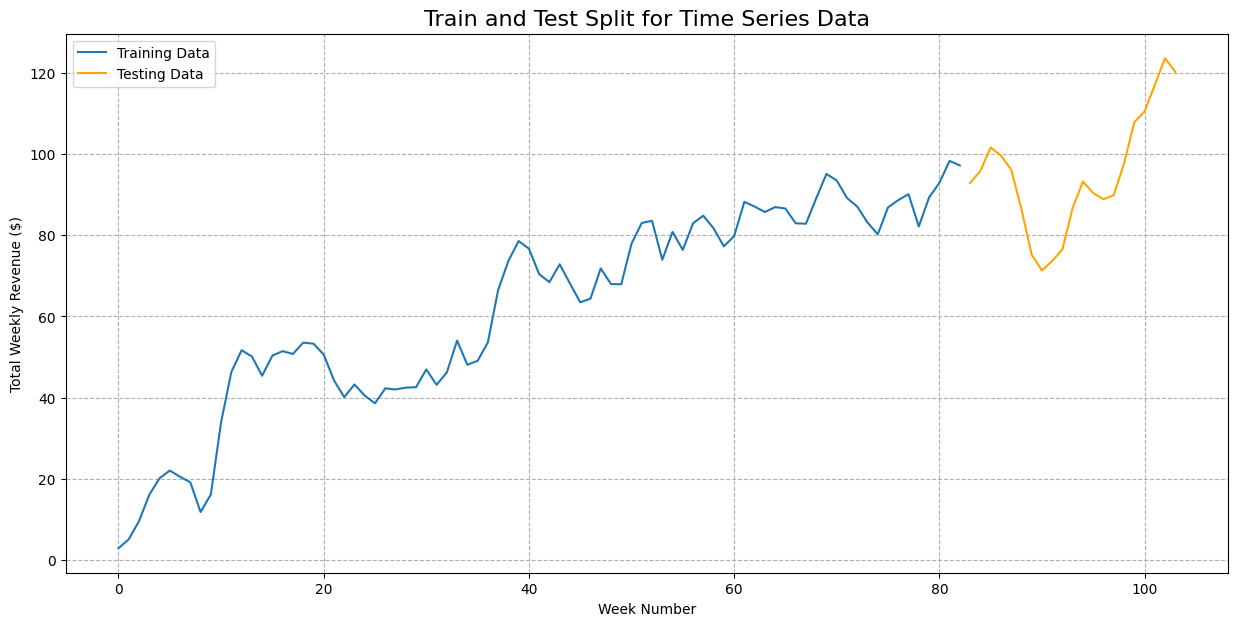

In [ ]:
# Stationary Series Plot
header_txt("Plotting Change in Revenues")
daily_data['revenue_diff'] = daily_data['Revenue'].diff()
daily_data_diff = daily_data.dropna() # the first row will be empty because of the .diff()

weekly_data['revenue_diff'] = weekly_data['Revenue'].diff()
weekly_data_diff = weekly_data.dropna() # the first row will be empty because of the .diff()

monthly_data['revenue_diff'] = monthly_data['Revenue'].diff()
monthly_data_diff = monthly_data.dropna() # the first row will be empty because of the .diff()

# construct plot
fig, axes = plt.subplots(2, 3, figsize = (20, 10))
title = "Comparing Original and Differenced Series"
fig.suptitle(title, fontsize = 18, fontweight = 'bold')

# original data
axes[0, 0].plot(daily_data.index, daily_data['Revenue'], label = 'Original Daily Data', color = 'magenta')
axes[0, 0].set_title("Original Daily Series with Trend", fontsize = 14)
axes[0, 0].set_ylabel("Total Daily Revenue ($)", fontsize = 12)
axes[0, 0].grid(True, linestyle = '--', linewidth = 0.5)
axes[0, 0].legend()

axes[0, 1].plot(weekly_data.index, weekly_data['Revenue'], label = 'Original Weekly Data', color = 'magenta')
axes[0, 1].set_title("Original Weekly Series with Trend", fontsize = 14)
axes[0, 1].set_ylabel("Total Weekly Revenue ($)", fontsize = 12)
axes[0, 1].grid(True, linestyle = '--', linewidth = 0.5)
axes[0, 1].legend()

axes[0, 2].plot(monthly_data.index, monthly_data['Revenue'], label = 'Original Monthly Data', color = 'magenta')
axes[0, 2].set_title("Original Monthly Series with Trend", fontsize = 14)
axes[0, 2].set_ylabel("Total Monthly Revenue ($)", fontsize = 12)
axes[0, 2].grid(True, linestyle = '--', linewidth = 0.5)
axes[0, 2].legend()



# differenced data
axes[1, 0].plot(daily_data_diff.index, daily_data_diff['revenue_diff'], label = 'Diffrenced Daily Revenue', color = 'green')
axes[1, 0].set_title("Differenced Daily Series (Stationary)", fontsize = 14)
axes[1, 0].set_ylabel("Change in Daily Revenue ($)", fontsize = 12)
axes[1, 0].set_xlabel("Day Number", fontsize = 8)
axes[1, 0].grid(True, linestyle = '--', linewidth = 0.5)
axes[1, 0].legend()

axes[1, 1].plot(weekly_data_diff.index, weekly_data_diff['revenue_diff'], label = 'Diffrenced Weekly Revenue', color = 'green')
axes[1, 1].set_title("Differenced Weekly Series (Stationary)", fontsize = 14)
axes[1, 1].set_ylabel("Change in Weekly Revenue ($)", fontsize = 12)
axes[1, 1].set_xlabel("Week Number", fontsize = 12)
axes[1, 1].grid(True, linestyle = '--', linewidth = 0.5)
axes[1, 1].legend()

axes[1, 2].plot(monthly_data_diff.index, monthly_data_diff['revenue_diff'], label = 'Diffrenced Monthly Revenue', color = 'green')
axes[1, 2].set_title("Differenced Monthly Series (Stationary)", fontsize = 14)
axes[1, 2].set_ylabel("Change in Monthly Revenue ($)", fontsize = 12)
axes[1, 2].set_xlabel("Month Number", fontsize = 12)
axes[1, 2].grid(True, linestyle = '--', linewidth = 0.5)
axes[1, 2].legend()


plt.tight_layout(rect = [0,0,1,0.95])
plt.savefig(f"{path}{title}")


# split the data for analysis
header_txt("test/train split")
split_point = int(len(weekly_data) * 0.8)

train = weekly_data.iloc[:split_point]
test = weekly_data.iloc[split_point:]

train.to_csv(f"{path}train.csv")
test.to_csv(f"{path}test.csv")


title = "Train and Test Split for Time Series Data"
plt.figure(figsize=(15, 7))
plt.plot(train.index, train['Revenue'], label='Training Data')
plt.plot(test.index, test['Revenue'], label='Testing Data', color='orange')
plt.title(f'{title}', fontsize=16)
plt.xlabel('Week Number')
plt.ylabel('Total Weekly Revenue ($)')
plt.legend()
plt.grid(True, linestyle='--')
plt.savefig(f"{path}{title}")

D5.  Provide a copy of the cleaned dataset.
My clean, train, and test datasets will be included with my submission.

In [ ]:
# verify split
header_txt("Verifying Split")
print(f"Original Shape: {weekly_data.shape}")
print(f"Train shape:    {train.shape}")
print(f"Test shape:     {test.shape}")
print(f"\n Last day of Training")
print(train.tail(1))
print(f"First day of Training")
print(train.head(1))


******************** Verifying Split ********************

Original Shape: (104, 3)
Train shape:    (83, 3)
Test shape:     (21, 3)

 Last day of Training
    Week    Revenue  revenue_diff
82    82  97.239222     -1.122787
First day of Training
   Week   Revenue  revenue_diff
0     0  2.830776           NaN


E1.  Report the annotated findings with visualizations of your data analysis, including the following elements:

The autocorrelation function:


******************** Autocorrelation Vizualization ********************



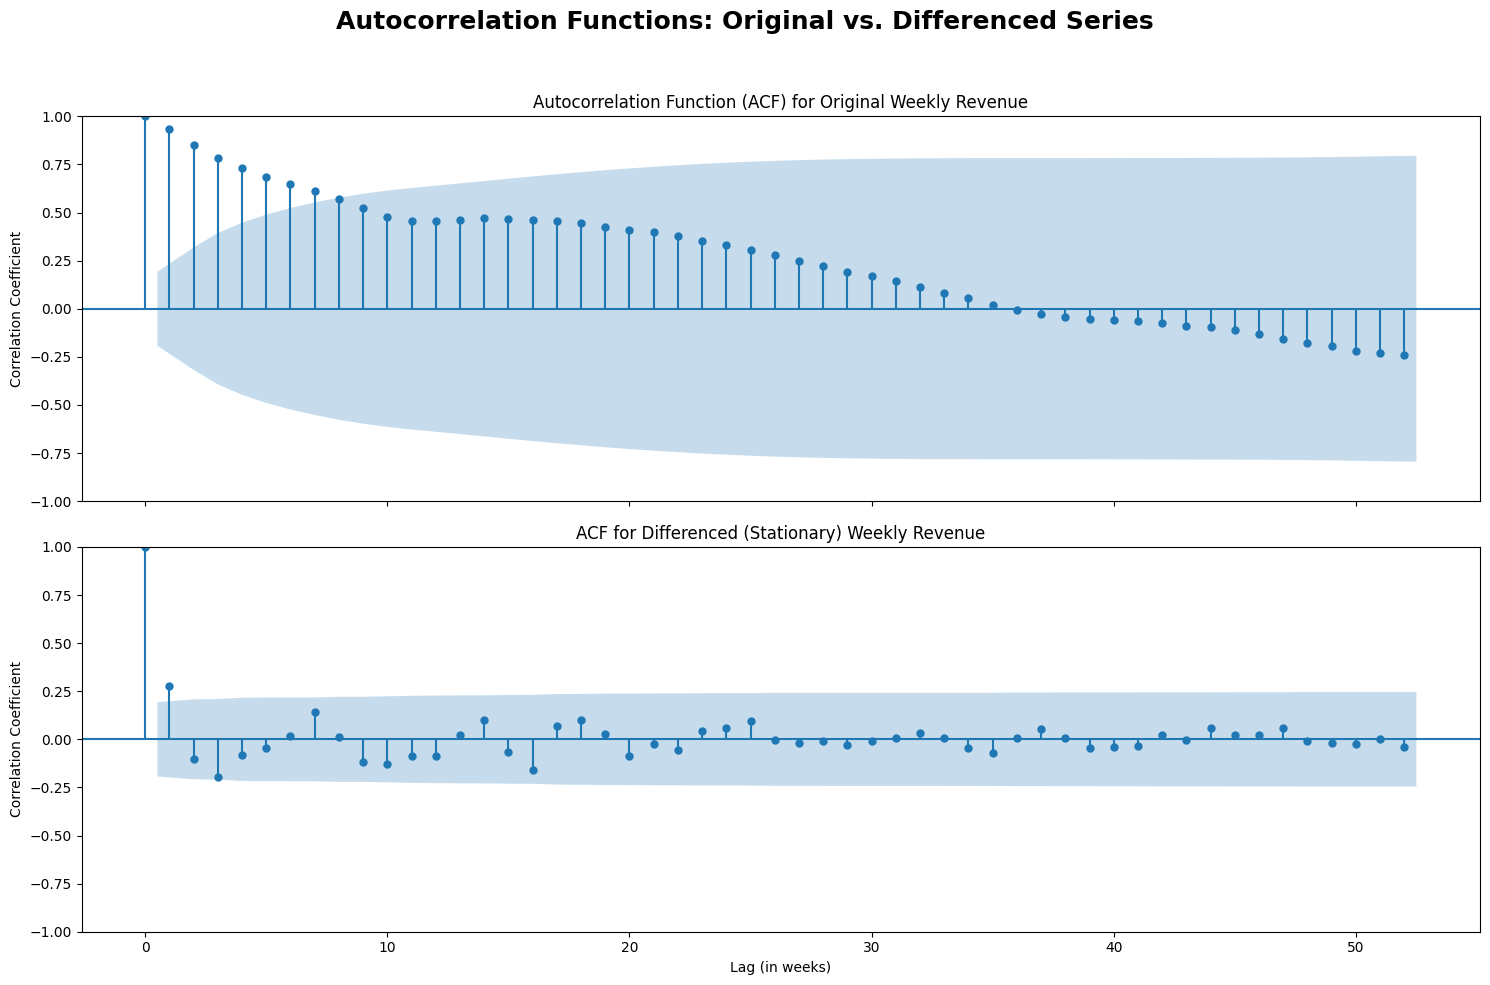

In [ ]:
header_txt("Autocorrelation Vizualization")



fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex = True)
title = "Autocorrelation Functions"
fig.suptitle(f'{title}: Original vs. Differenced Series', fontsize=18, fontweight='bold')
plot_acf(weekly_data['Revenue'], lags=52, ax=axes[0]) # Show lags up to one year (52 weeks)
axes[0].set_title('Autocorrelation Function (ACF) for Original Weekly Revenue')
axes[0].set_ylabel('Correlation Coefficient')

plot_acf(weekly_data_diff['revenue_diff'], lags=52, ax=axes[1])
axes[1].set_title('ACF for Differenced (Stationary) Weekly Revenue')
axes[1].set_xlabel('Lag (in weeks)')
axes[1].set_ylabel('Correlation Coefficient')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(f"{path}{title}")

The spectral density:


******************** Spectral Density ********************

The strongest frequency peak is at: 0.0096 cycles per week
This corresponds to a period of: 104.00 weeks


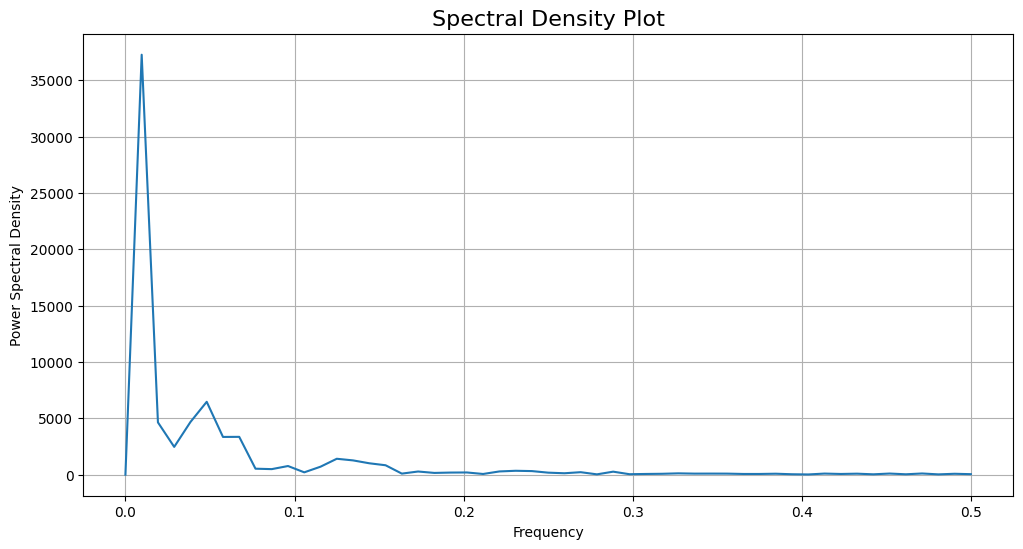

In [ ]:
header_txt("Spectral Density")

frequencies, density = periodogram(weekly_data['Revenue'], fs = 1)

# visualization
plt.figure(figsize=(12, 6))
plt.plot(frequencies, density)
plt.title('Spectral Density Plot', fontsize=16)
plt.xlabel('Frequency')
plt.ylabel('Power Spectral Density')
plt.grid(True)
plt.savefig(f"{path}spectral density")

# strongest peak
peak_frequency = frequencies[density.argmax()]
print(f"The strongest frequency peak is at: {peak_frequency:.4f} cycles per week")
# period is the inverse of the frequency
peak_period = 1 / peak_frequency
print(f"This corresponds to a period of: {peak_period:.2f} weeks")

The decomposed time series:


******************** Decomposition Graph ********************



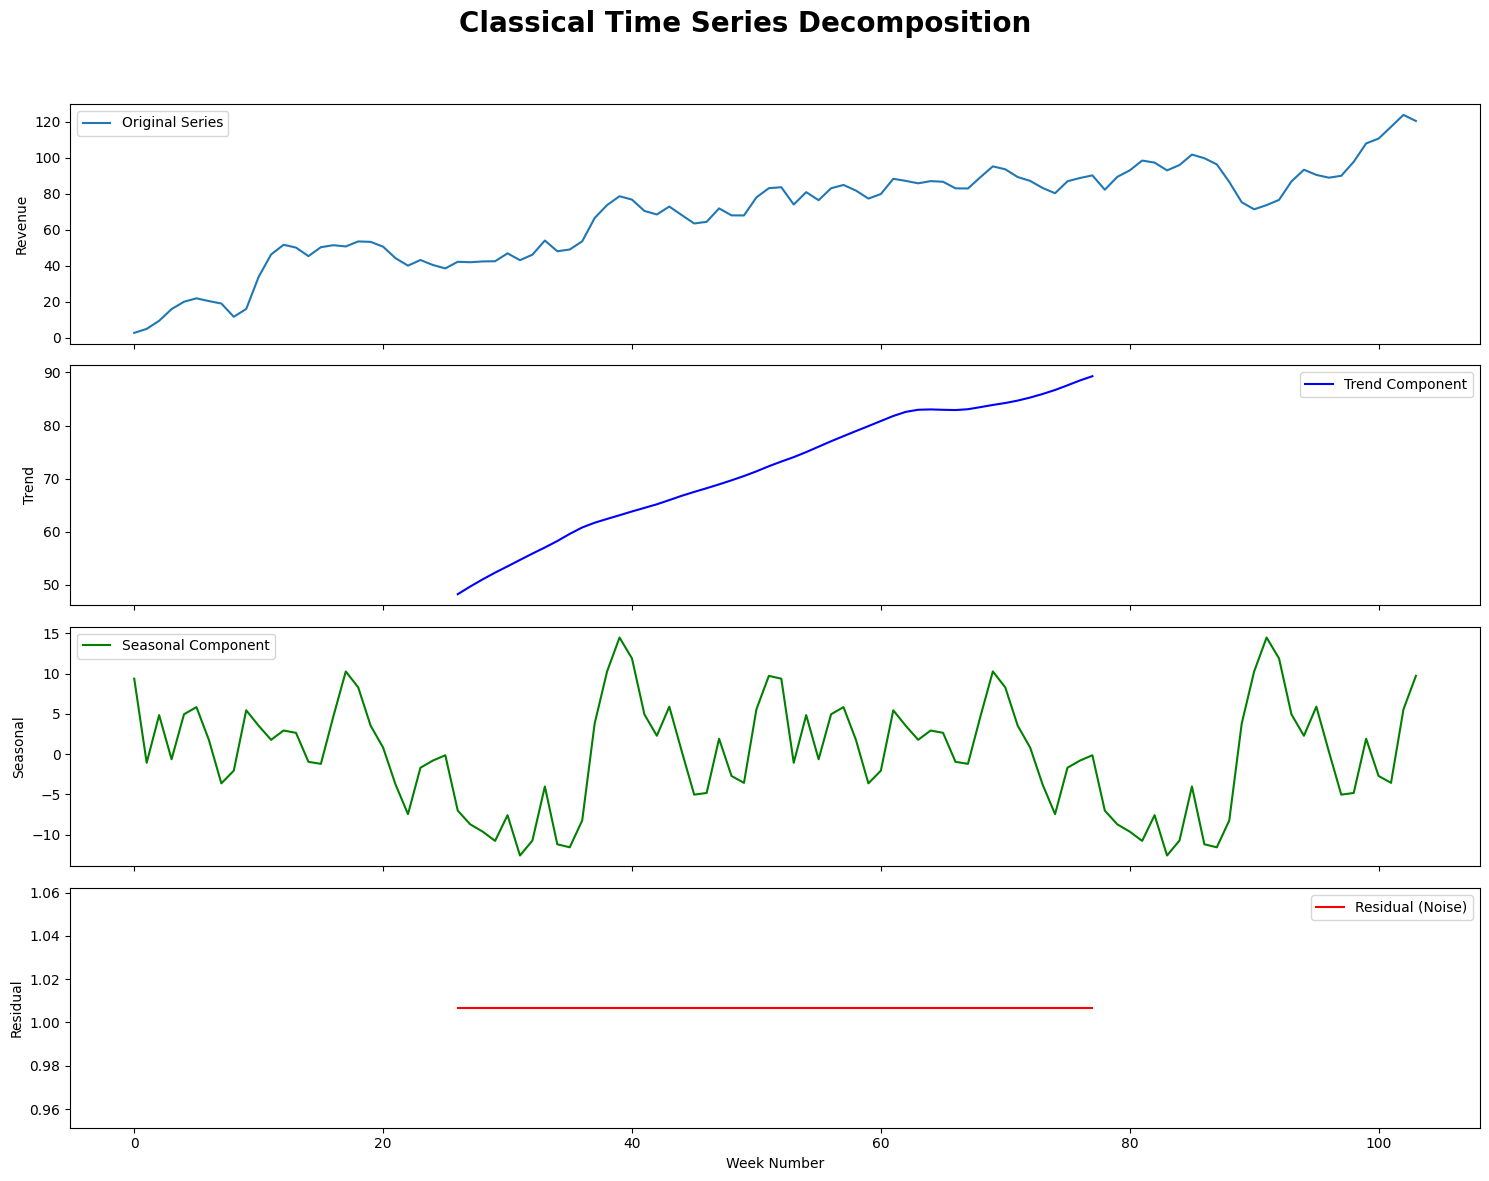

In [ ]:
header_txt("Decomposition Graph")
decomposition = seasonal_decompose(weekly_data['Revenue'], model= 'additive', period = 52)
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

fig, axes = plt.subplots(4, 1, figsize = (15, 12), sharex= True)
title = "Classical Time Series Decomposition"
fig.suptitle(f"{title}", fontsize = 20, fontweight = 'bold')

# original
axes[0].plot(weekly_data['Revenue'], label='Original Series')
axes[0].set_ylabel('Revenue')
axes[0].legend()

# trend
axes[1].plot(trend, label='Trend Component', color='blue')
axes[1].set_ylabel('Trend')
axes[1].legend()

# seasonal
axes[2].plot(seasonal, label='Seasonal Component', color='green')
axes[2].set_ylabel('Seasonal')
axes[2].legend()

# residual
axes[3].plot(residual, label='Residual (Noise)', color='red')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Week Number')
axes[3].legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(f"{path}{title}")

The trends and confirmation of the lack of trends in the residuals of the decomposed series:

The residual of the trend line is horizontal, which implies that the graph has captured the entire trend. A non-horizontal trend line shows the noise, or, the parts of the data not captured by the current model.

E2.  Identify an autoregressive integrated moving average (ARIMA) model that accounts for the observed trend and seasonality of the time series data.


******************** Train and test ARIMA model ********************

Drift of training data is: 1.1513


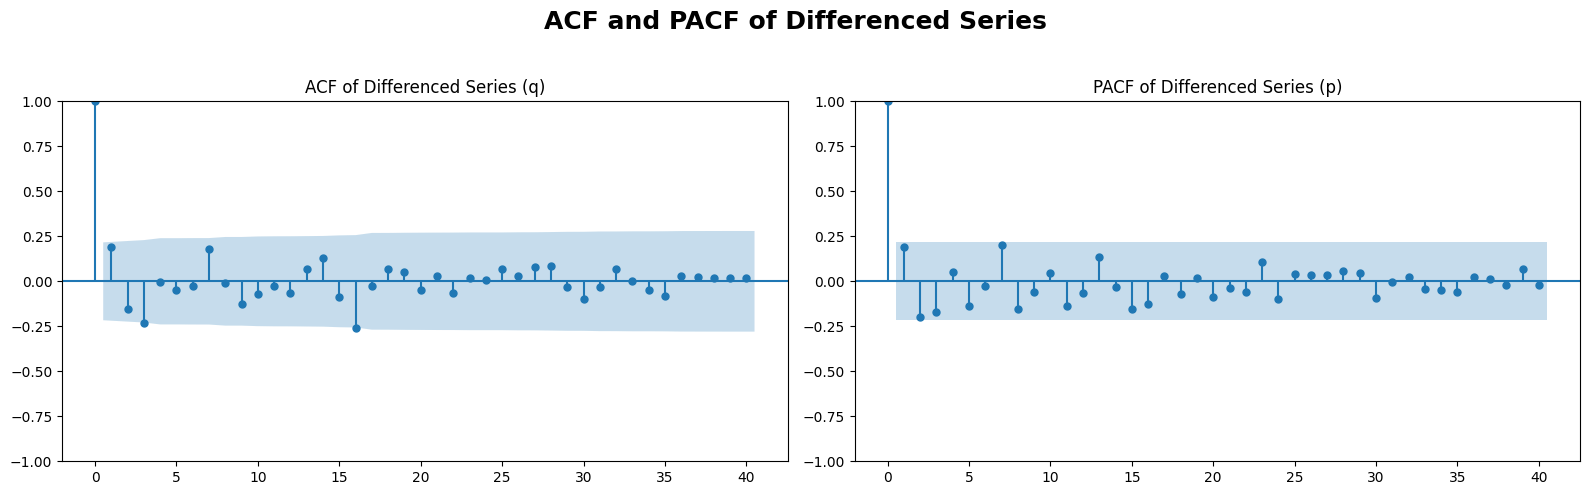

In [ ]:
header_txt("Train and test ARIMA model")
train_diff = train['Revenue'].diff().dropna()
drift = train_diff.mean()
print(f"Drift of training data is: {drift:.4f}")

title = "ACF and PACF of Differenced Series"
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f'{title}', fontsize=18, fontweight='bold')
# ACF
plot_acf(train_diff, lags=40, ax=axes[0])
axes[0].set_title('ACF of Differenced Series (q)')

# PACF
plot_pacf(train_diff, lags=40, ax=axes[1])
axes[1].set_title('PACF of Differenced Series (p)')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(f"{path}{title}")


In [ ]:
# ARIMA model parameters based off of CI test
p, d, q = 1, 1, 3

my_test = [1, 1, 3]
simple_exponential = [0, 1, 1]
default = [1, 1, 0]
very_simple = [0, 1, 3]

to_test = [my_test, simple_exponential, default, very_simple]

best_aic = float('inf')
best_model_summary = None

def test_model(arima_model, p, d, q, train = train):
    model = ARIMA(train['Revenue'], order = (p, d, q)).fit()
    current_aic = model.aic
    return model, current_aic

for i in to_test:
    header_txt(f"Model Summary for {i}")
    current_model, current_aic = test_model(i, i[0], i[1], i[2], train = train)
    if current_aic < best_aic:
        best_aic = current_aic
        best_model = current_model
        print("NEW BEST!")
        print(best_model.summary())



******************** Model Summary for [1, 1, 3] ********************

NEW BEST!
                               SARIMAX Results                                
Dep. Variable:                Revenue   No. Observations:                   83
Model:                 ARIMA(1, 1, 3)   Log Likelihood                -245.754
Date:                Tue, 14 Apr 2026   AIC                            501.509
Time:                        09:24:26   BIC                            513.542
Sample:                             0   HQIC                           506.340
                                 - 83                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1538      0.413     -0.373      0.709      -0.963       0.655
ma.L1          0.4379      0.431      1.017      

E3.  Perform a forecast using the derived ARIMA model identified in part E2.

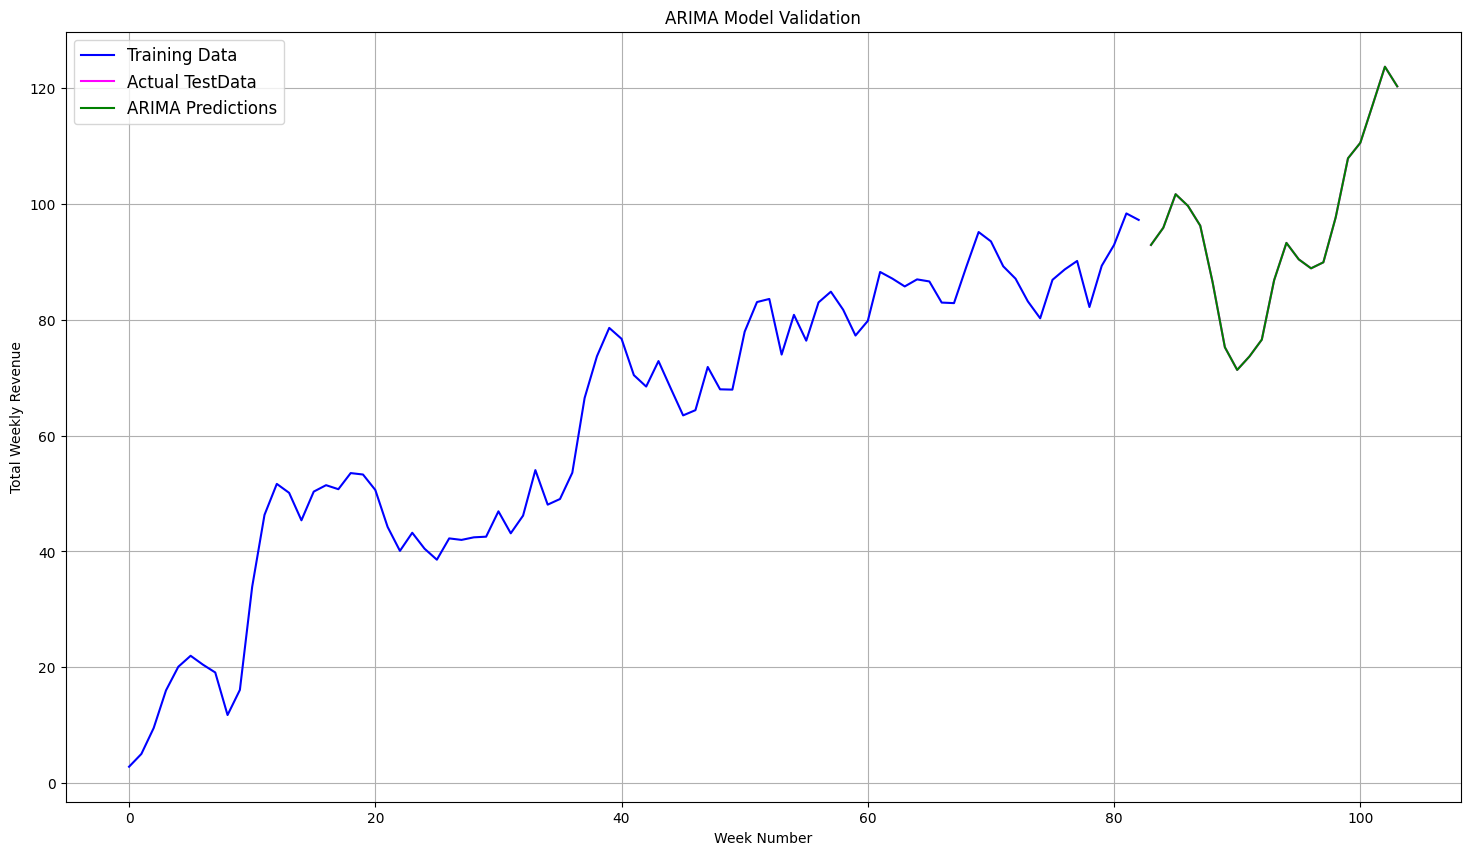

In [ ]:
start_index = test.index[0]
end_index = test.index[-1]

predictions = best_model.predict(start = start_index, end = end_index)

plt.figure(figsize = (18, 10))
plt.plot(train.index, train['Revenue'], label = 'Training Data', color = 'blue')
plt.plot(test.index, test['Revenue'], label = 'Actual TestData', color = 'magenta')
plt.plot(predictions.index, test['Revenue'], label = "ARIMA Predictions", color = 'green')

title = "ARIMA Model Validation"
plt.title(f"{title}")
plt.xlabel("Week Number")
plt.ylabel("Total Weekly Revenue")
plt.legend(fontsize = 12)
plt.grid(True)
plt.savefig(f"{path}{title}")

E4.  Provide the output and calculations of the analysis you performed.


******************** FORECAST ********************



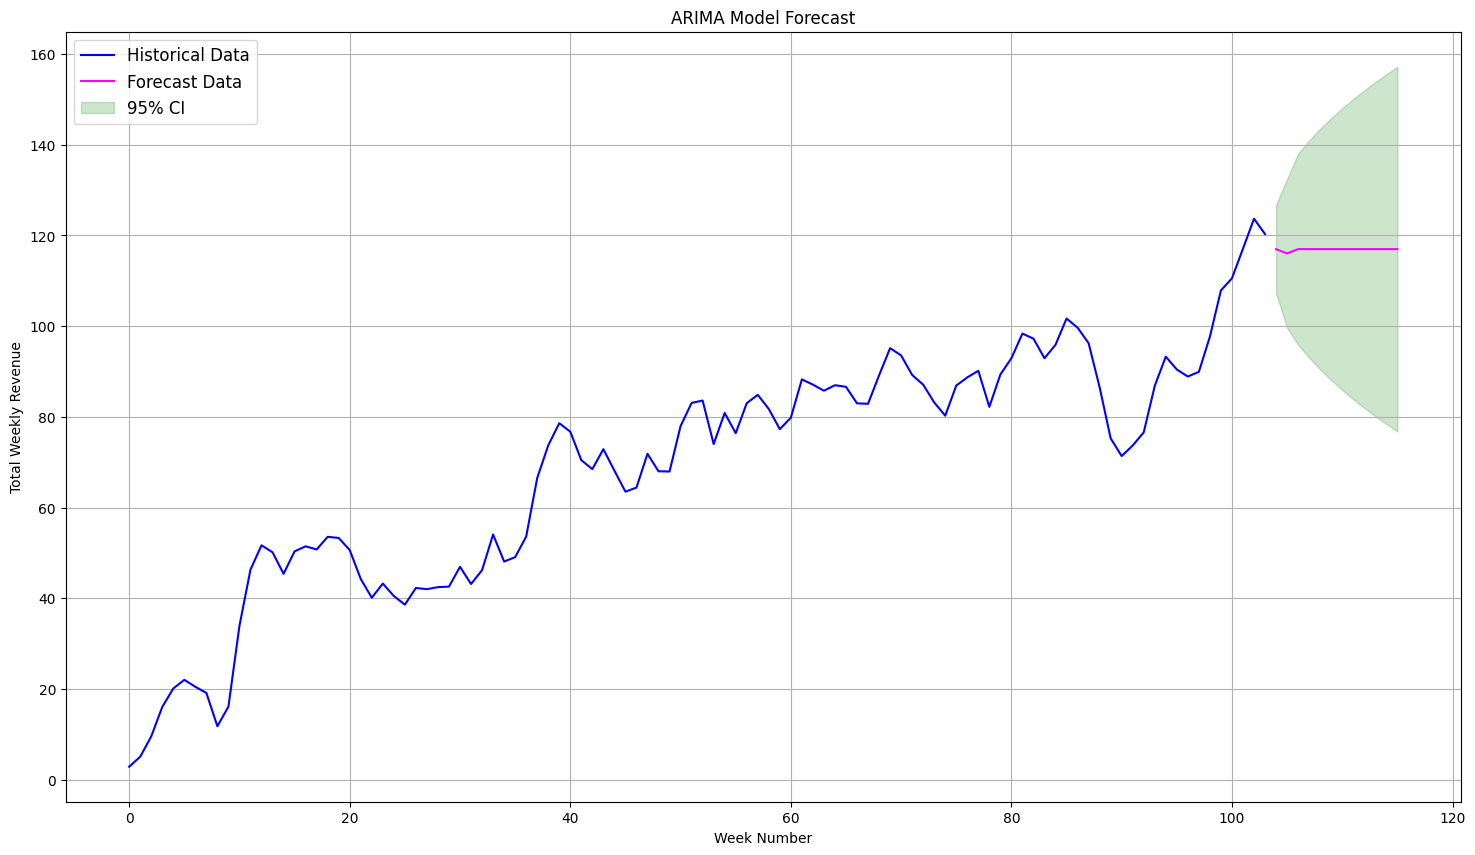

In [ ]:
header_txt("FORECAST")
full_model = ARIMA(weekly_data['Revenue'], order = very_simple, trend = "t").fit()
n_periods_to_forecast = 12

forecast = full_model.get_forecast(steps = n_periods_to_forecast)
mean_forecast = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

plt.figure(figsize = (18, 10))
plt.plot(weekly_data.index, weekly_data['Revenue'], label = 'Historical Data', color = 'blue')
plt.plot(mean_forecast.index, mean_forecast.values, label = 'Forecast Data', color = 'magenta')

plt.fill_between(
    confidence_intervals.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color = 'green',
    alpha = .2,
    label = '95% CI'
)

title = "ARIMA Model Forecast"
plt.title(f"{title}")
plt.xlabel("Week Number")
plt.ylabel("Total Weekly Revenue")
plt.legend(fontsize = 12)
plt.grid(True)
plt.savefig(f"{path}{title}")

forecast_summary = pd.concat([mean_forecast, confidence_intervals], axis = 1)
forecast_summary.columns = ['Forecasted_Revenue', "Lower_95_CI", "Upper_95_CI"]
forecast_summary.index.name = 'Week'

F1.  Discuss the results of your data analysis, including the following:
•   the selection of an ARIMA model
After graphing the ACF and PACF of the diffrerendced series I was able to get inital predictions for my p and q for my ARIMA model. I made a list of different parameters and looped that through my initial model to determine the most effective ARIMA model by keeping teh one with the lowest AIC. My initial analysis revealed that a simplified version of my initial prediction was the most accurate model.
•   the prediction interval of the forecast
I used the industry standard of a 95% predicion interval, or confidence interval, shaded green.
•   a justification of the forecast length
I used a forcast length of 12 weeks, or aproximately one quarter. This is a traditional business timeframs and can hopefully predict next quarters trend.
•   the model evaluation procedure and error metric


F2.  Provide an annotated visualization of the forecast of the final model compared to the test set that includes the following:
•   the original output with the new prediction line and confidence cone
•   correct labeling


******************** FORECAST ********************



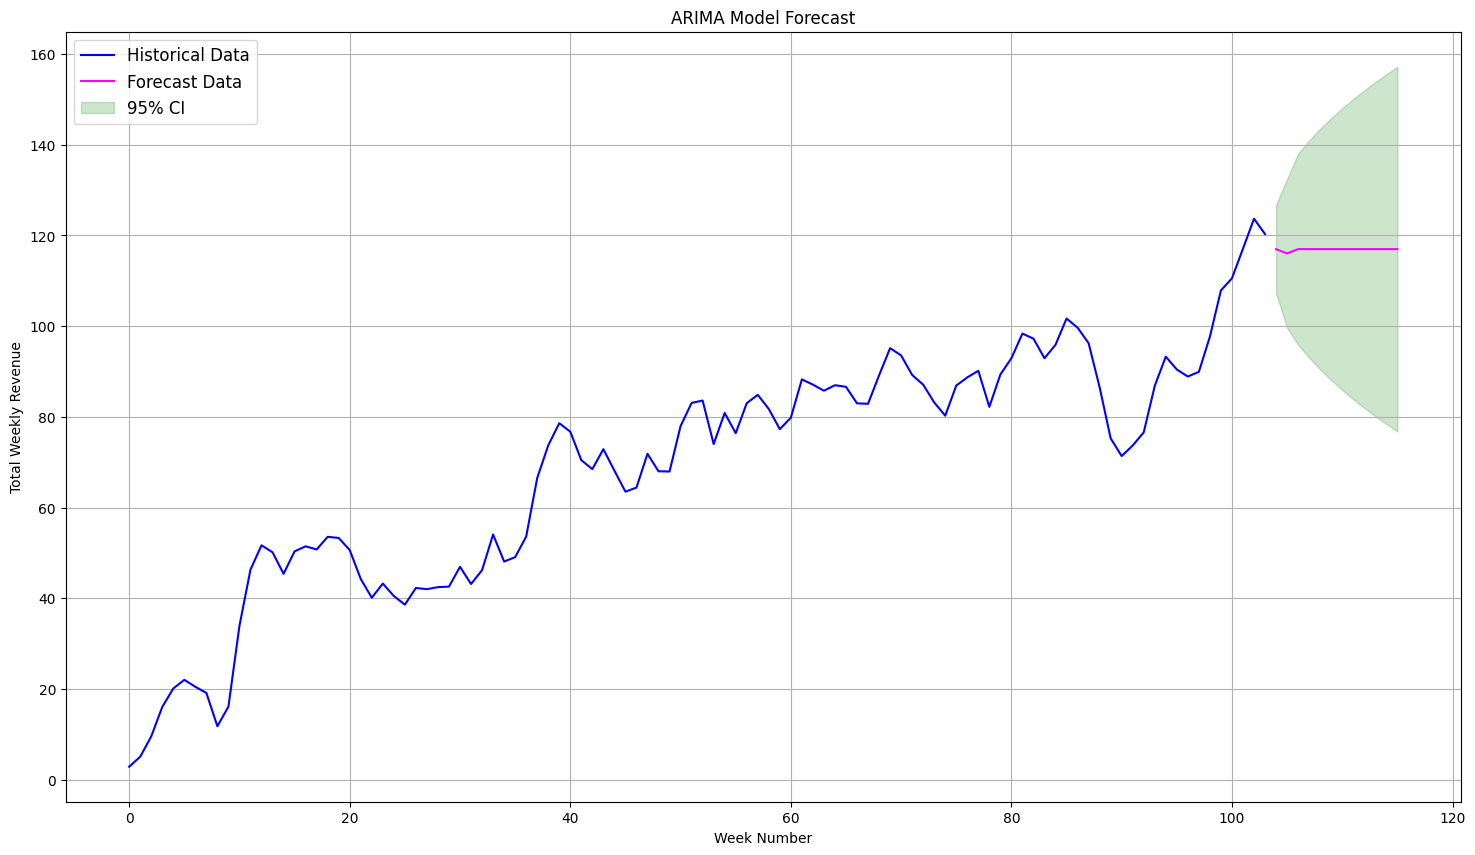

In [ ]:
header_txt("FORECAST")
full_model = ARIMA(weekly_data['Revenue'], order = very_simple).fit()
n_periods_to_forecast = 12

forecast = full_model.get_forecast(steps = n_periods_to_forecast)
mean_forecast = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

plt.figure(figsize = (18, 10))
plt.plot(weekly_data.index, weekly_data['Revenue'], label = 'Historical Data', color = 'blue')
plt.plot(mean_forecast.index, mean_forecast.values, label = 'Forecast Data', color = 'magenta')

plt.fill_between(
    confidence_intervals.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color = 'green',
    alpha = .2,
    label = '95% CI'
)

title = "ARIMA Model Forecast"
plt.title(f"{title}")
plt.xlabel("Week Number")
plt.ylabel("Total Weekly Revenue")
plt.legend(fontsize = 12)
plt.grid(True)
plt.savefig(f"{path}{title}")

forecast_summary = pd.concat([mean_forecast, confidence_intervals], axis = 1)
forecast_summary.columns = ['Forecasted_Revenue', "Lower_95_CI", "Upper_95_CI"]
forecast_summary.index.name = 'Week'

F3.  Recommend a course of action based on your results.

There appears to be a dip in weekly revenue a few weeks after the forecast begins. This analysis is useful for identifying trends, but not quantifying why they happen, so I would recommend constructing a data call to capture as much data as possible for the next month and then do structured and unstructured machine learnign to glean more information on why this season is weaker than others.